# Financial News Sentiment Analysis
> **Course:** Natural Language Processing (NLP) Final Project
> **Professor:** Asmaa Benzmane
> **Author:** Yves Abdallah

---

## Project Overview
Sentiment analysis is a crucial sub-field of Natural Language Processing (NLP) that focuses on determining the emotional tone behind textual data. This project explores various techniques for sentiment analysis on **Financial News**, comparing traditional machine learning models (like SVM and Logistic Regression) with advanced deep learning architectures (Bi-LSTM and FinBERT).

### Objective
To evaluate the effectiveness of these models in classifying financial sentences as:
- **Positive** 
- **Negative** 
- **Neutral** 

### NLP Workflow Implemented
1. **Data Collection:** Utilizing a diverse financial news dataset.
2. **Preprocessing:** Cleaning, Tokenization, Stopword Removal, and Lemmatization.
3. **Feature Extraction:** TF-IDF for Traditional ML, and Word/Subword Embeddings for Deep Learning.
4. **Model Training:** Scikit-Learn (ML), TensorFlow (LSTM), PyTorch & HuggingFace (FinBERT).
5. **Evaluation:** Accuracy, Precision, Recall, and F1-Score.
6. **Analysis:** Detailed comparison of performance, trade-offs, and NLP challenges like ambiguity.


---
## 1. Data Collection & Environment Setup
We begin by installing necessary libraries and loading our financial news dataset. We will also visualize the distribution of sentiments to understand our data better.


Loading dataset...


,Sentence,Sentiment
0,The GeoSolutions technology will leverage Bene...,positive
1,"$ESI on lows, down $1.50 to $2.50 BK a real po...",negative
2,"For the last quarter of 2010 , Componenta 's n...",positive
3,According to the Finnish-Russian Chamber of Co...,neutral
4,The Swedish buyout firm has sold its remaining...,neutral


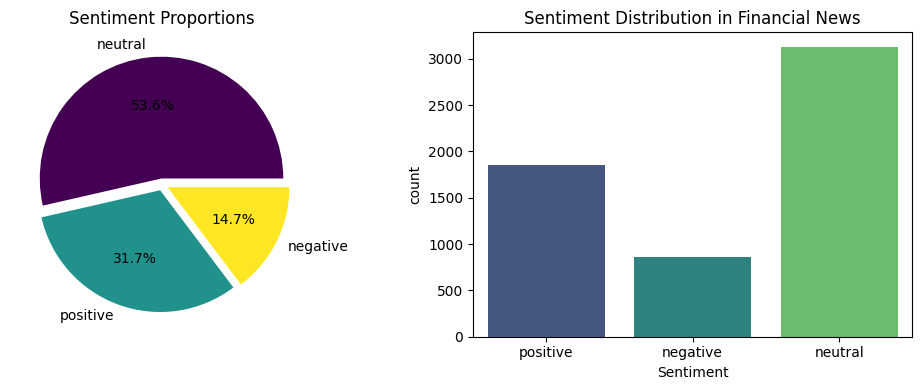

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.metrics import confusion_matrix
import warnings
warnings.filterwarnings('ignore')

# Ensure plots display properly
%matplotlib inline

# Load dataset
print("Loading dataset...")
df = pd.read_csv("financial-news-sentiment.csv")
df = df.dropna()

display(df.head())

# Visualizing Sentiment Distribution
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
df['Sentiment'].value_counts().plot.pie(autopct='%1.1f%%', cmap='viridis', explode=(0.05, 0.05, 0.05))
plt.title('Sentiment Proportions')
plt.ylabel('')

plt.subplot(1, 2, 2)
sns.countplot(data=df, x='Sentiment', hue='Sentiment', palette='viridis', legend=False)
plt.title('Sentiment Distribution in Financial News')
plt.tight_layout()
plt.show()


---
## 2. Preprocessing & Data Splitting
Text data is extremely noisy. To prepare it for our models, we apply a strict cleaning pipeline:
- **Lowercasing:** To ensure uniformity (e.g., 'Market' and 'market' are treated as the same word).
- **Removing Punctuation:** Filtering out special characters while preserving numbers (which carry financial context).
- **Stopword Removal:** Eliminating frequent but uninformative words like 'is', 'the', and 'and'.
- **Lemmatization:** Reducing words to their base root (e.g., 'running' -> 'run').

We also split our data into **Train (70%)**, **Validation (15%)**, and **Test (15%)** sets to prevent data leakage.


In [18]:
from sklearn.model_selection import train_test_split

X_temp, X_test, y_temp, y_test = train_test_split(df['Sentence'], df['Sentiment'], test_size=0.15, random_state=42, stratify=df['Sentiment'])
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.1765, random_state=42, stratify=y_temp)

print(f"Training set: {len(X_train)} samples")
print(f"Validation set: {len(X_val)} samples")
print(f"Testing set: {len(X_test)} samples\n")

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
 text = text.lower()
 text = re.sub(r'[^a-z0-9\s]', '', text) 
 words = text.split()
 words = [lemmatizer.lemmatize(w) for w in words if w not in stop_words]
 return ' '.join(words)

print("Applying preprocessing pipeline...")
X_train_clean = X_train.apply(clean_text)
X_val_clean = X_val.apply(clean_text)
X_test_clean = X_test.apply(clean_text)
print("Preprocessing complete!")


Training set: 4088 samples
Validation set: 877 samples
Testing set: 877 samples

Applying preprocessing pipeline...
Preprocessing complete!


---
## 3. Feature Extraction & Traditional ML Models
We extract features using **TF-IDF (Term Frequency-Inverse Document Frequency)** combined with Bigrams `ngram_range=(1, 2)`. This transforms our text into numerical weights based on word importance.

We train and compare four classic algorithms:
1. **Logistic Regression**
2. **Support Vector Machine (SVM)**
3. **Naive Bayes**
4. **Random Forest**



Training Logistic Regression...
              precision    recall  f1-score   support

    negative       0.38      0.53      0.44       129
     neutral       0.78      0.72      0.75       470
    positive       0.73      0.68      0.70       278

    accuracy                           0.68       877
   macro avg       0.63      0.64      0.63       877
weighted avg       0.70      0.68      0.69       877


Training SVM...
              precision    recall  f1-score   support

    negative       0.34      0.56      0.42       129
     neutral       0.78      0.70      0.74       470
    positive       0.74      0.64      0.69       278

    accuracy                           0.66       877
   macro avg       0.62      0.63      0.62       877
weighted avg       0.70      0.66      0.68       877


Training Naive Bayes...
              precision    recall  f1-score   support

    negative       0.43      0.08      0.13       129
     neutral       0.68      0.93      0.78       470


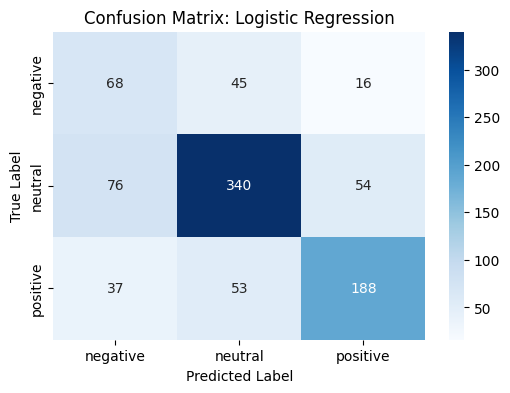

In [19]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier

# TF-IDF Vectorization
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_tfidf = vectorizer.fit_transform(X_train_clean)
X_val_tfidf = vectorizer.transform(X_val_clean)
X_test_tfidf = vectorizer.transform(X_test_clean)

f1_scores = {}
best_ml_model_name = ""
best_ml_f1 = 0
best_ml_y_pred = None

ml_models = {
 "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced'),
 "SVM": SVC(kernel='linear', class_weight='balanced'),
 "Naive Bayes": MultinomialNB(),
 "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced')
}

for name, model in ml_models.items():
 print(f"\n{'='*40}\nTraining {name}...\n{'='*40}")
 model.fit(X_train_tfidf, y_train)
 y_pred = model.predict(X_test_tfidf)
 
 f1 = f1_score(y_test, y_pred, average='weighted')
 f1_scores[name] = f1
 if f1 > best_ml_f1:
 best_ml_f1 = f1
 best_ml_model_name = name
 best_ml_y_pred = y_pred
 
 print(classification_report(y_test, y_pred))

# Plot confusion matrix for the best ML Model
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test, best_ml_y_pred, labels=['negative', 'neutral', 'positive'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['negative', 'neutral', 'positive'], yticklabels=['negative', 'neutral', 'positive'])
plt.title(f'Confusion Matrix: {best_ml_model_name}')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()


---
## 4. Advanced Deep Learning Models
While ML models are fast, they ignore the sequential nature of text. Deep Learning models like **Bi-LSTMs** learn from the order of words using dense Word Embeddings.

### 4.1. The Overfitting Problem (Demonstration)
Deep Learning models are highly complex. When trained on a relatively small dataset (~4000 samples), they tend to memorize the data rather than learn general patterns. Let's observe this phenomenon by training a Bi-LSTM **without** any early stopping limits.


Training Bi-LSTM WITHOUT Early Stopping (15 Epochs)...


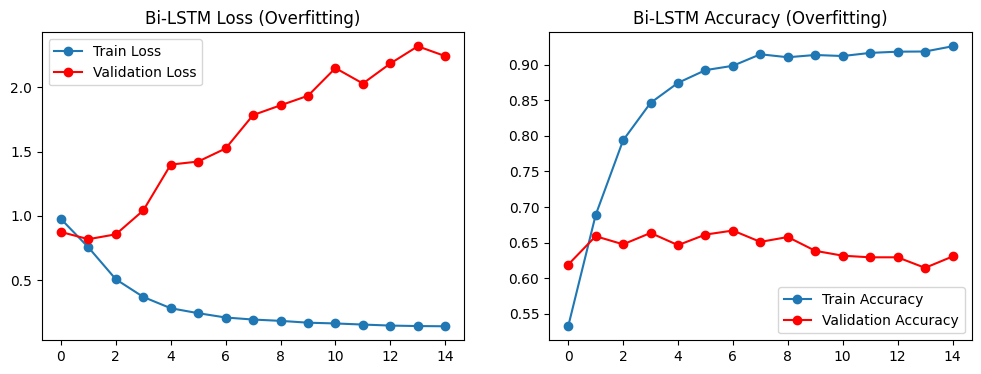

Final Test F1-Score (Overfitted): 0.648


In [20]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping

# Encode Labels
label_map = {'negative': 0, 'neutral': 1, 'positive': 2}
y_train_num = y_train.map(label_map).values
y_val_num = y_val.map(label_map).values
y_test_num = y_test.map(label_map).values

# Tokenization & Padding
max_words = 5000
max_len = 50

tokenizer = Tokenizer(num_words=max_words)
tokenizer.fit_on_texts(X_train_clean)

X_train_seq = pad_sequences(tokenizer.texts_to_sequences(X_train_clean), maxlen=max_len)
X_val_seq = pad_sequences(tokenizer.texts_to_sequences(X_val_clean), maxlen=max_len)
X_test_seq = pad_sequences(tokenizer.texts_to_sequences(X_test_clean), maxlen=max_len)

def build_bilstm():
 model = tf.keras.Sequential([
 tf.keras.layers.Embedding(input_dim=max_words, output_dim=128),
 tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64)),
 tf.keras.layers.Dropout(0.5),
 tf.keras.layers.Dense(32, activation='relu'),
 tf.keras.layers.Dropout(0.5),
 tf.keras.layers.Dense(3, activation='softmax')
 ])
 model.compile(loss='sparse_categorical_crossentropy', optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), metrics=['accuracy'])
 return model

print("Training Bi-LSTM WITHOUT Early Stopping (15 Epochs)...")
model_overfit = build_bilstm()
history_overfit = model_overfit.fit(
 X_train_seq, y_train_num, 
 epochs=15, batch_size=32, 
 validation_data=(X_val_seq, y_val_num), 
 verbose=0
)

# Plot Overfitting Curves
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_overfit.history['loss'], label='Train Loss', marker='o')
plt.plot(history_overfit.history['val_loss'], label='Validation Loss', color='red', marker='o')
plt.title('Bi-LSTM Loss (Overfitting)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_overfit.history['accuracy'], label='Train Accuracy', marker='o')
plt.plot(history_overfit.history['val_accuracy'], label='Validation Accuracy', color='red', marker='o')
plt.title('Bi-LSTM Accuracy (Overfitting)')
plt.legend()
plt.show()

y_pred_overfit = np.argmax(model_overfit.predict(X_test_seq, verbose=0), axis=1)
f1_scores['Bi-LSTM (Overfit)'] = f1_score(y_test_num, y_pred_overfit, average='weighted')
print(f"Final Test F1-Score (Overfitted): {f1_scores['Bi-LSTM (Overfit)']:.3f}")


### Understanding the Curves & Fixing the Issue

As seen in the red curves above, around Epoch 2 or 3, the model starts memorizing the data. The Training Loss keeps dropping perfectly, but the Validation Loss sharply **increases**, confirming a severe loss of generalization.

### 4.2. The Solution: Early Stopping
To remedy this, we implement the **`EarlyStopping`** mechanism. 
It monitors the Validation Loss and halts the training immediately when degradation is detected for 3 consecutive epochs. Most importantly, it automatically discards the overfitted weights and **restores the optimal weights**.


Training Bi-LSTM WITH Early Stopping...


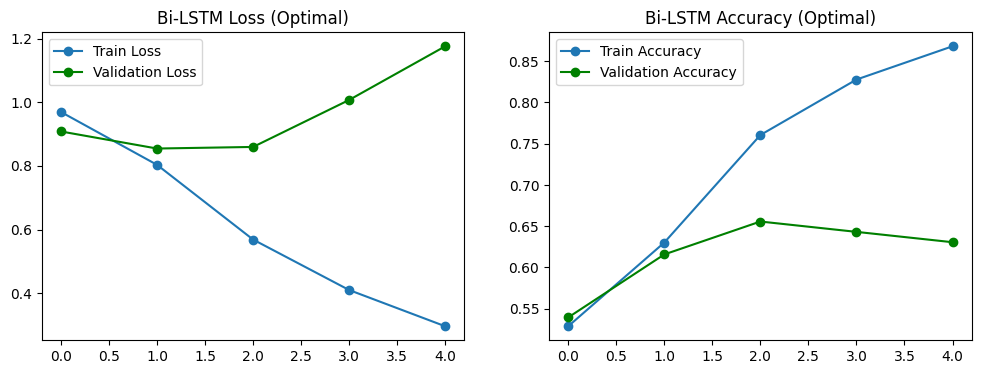


Bi-LSTM Test Performance (Optimal):

              precision    recall  f1-score   support

    negative       0.35      0.17      0.23       129
     neutral       0.67      0.83      0.74       470
    positive       0.65      0.54      0.59       278

    accuracy                           0.64       877
   macro avg       0.56      0.51      0.52       877
weighted avg       0.62      0.64      0.62       877



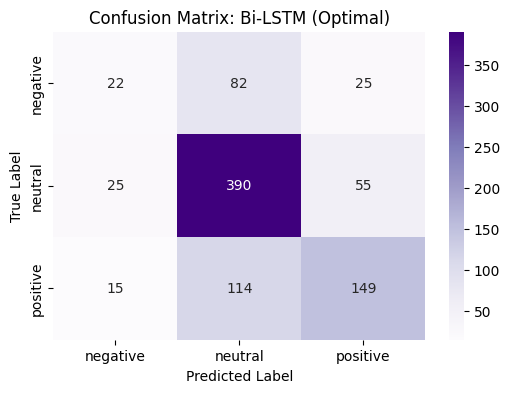

In [21]:
print("Training Bi-LSTM WITH Early Stopping...")
model_early = build_bilstm()
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history_early = model_early.fit(
 X_train_seq, y_train_num, 
 epochs=15, batch_size=32, 
 validation_data=(X_val_seq, y_val_num), 
 callbacks=[early_stop],
 verbose=0
)

# Plot Corrected Curves
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_early.history['loss'], label='Train Loss', marker='o')
plt.plot(history_early.history['val_loss'], label='Validation Loss', color='green', marker='o')
plt.title('Bi-LSTM Loss (Optimal)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_early.history['accuracy'], label='Train Accuracy', marker='o')
plt.plot(history_early.history['val_accuracy'], label='Validation Accuracy', color='green', marker='o')
plt.title('Bi-LSTM Accuracy (Optimal)')
plt.legend()
plt.show()

# Evaluate Corrected Model
y_pred_early = np.argmax(model_early.predict(X_test_seq, verbose=0), axis=1)
f1_scores['Bi-LSTM (Optimal)'] = f1_score(y_test_num, y_pred_early, average='weighted')

print("\nBi-LSTM Test Performance (Optimal):\n")
print(classification_report(y_test_num, y_pred_early, target_names=['negative', 'neutral', 'positive']))

plt.figure(figsize=(6, 4))
cm_lstm = confusion_matrix(y_test_num, y_pred_early)
sns.heatmap(cm_lstm, annot=True, fmt='d', cmap='Purples', xticklabels=['negative', 'neutral', 'positive'], yticklabels=['negative', 'neutral', 'positive'])
plt.title('Confusion Matrix: Bi-LSTM (Optimal)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()


---
### 4.3. Transformer-Based Model: FinBERT
Transformers represent the pinnacle of modern NLP. **FinBERT** is a state-of-the-art model pre-trained strictly on financial corpora (like SEC filings and financial news). It deeply understands financial nuances (e.g., that "bullish" is positive).

*Note: We pass the ORIGINAL (uncleaned) text to FinBERT because Transformers rely heavily on grammar and punctuation to deduce semantic relationships.*


Using device: cpu (GPU when available)

Evaluating FinBERT (Zero-Shot) on Test Set...


100%|██████████| 55/55 [00:18<00:00,  2.91it/s]


FinBERT Test Performance:

              precision    recall  f1-score   support

    positive       0.84      0.71      0.77       278
    negative       0.49      0.79      0.60       129
     neutral       0.81      0.75      0.78       470

    accuracy                           0.74       877
   macro avg       0.71      0.75      0.72       877
weighted avg       0.77      0.74      0.75       877



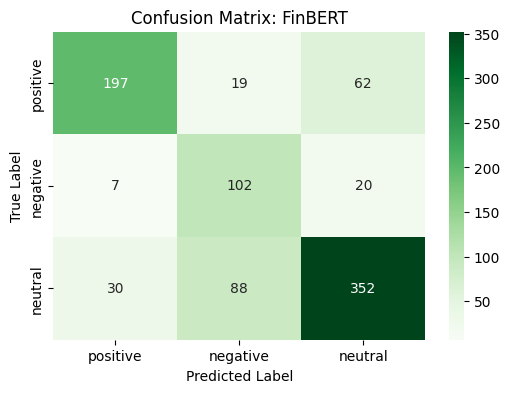

In [22]:
import torch
from transformers import BertTokenizer, BertForSequenceClassification
from torch.utils.data import DataLoader, TensorDataset
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device} (GPU when available)\n")

# Load Pre-trained FinBERT
model_name = "ProsusAI/finbert"
tokenizer_bert = BertTokenizer.from_pretrained(model_name)
model_bert = BertForSequenceClassification.from_pretrained(model_name, num_labels=3).to(device)

# Tokenize ORIGINAL text
encoded_test = tokenizer_bert(X_test.tolist(), padding=True, truncation=True, max_length=128, return_tensors="pt")
test_dataset = TensorDataset(encoded_test['input_ids'], encoded_test['attention_mask'])
test_loader = DataLoader(test_dataset, batch_size=16)

print("Evaluating FinBERT (Zero-Shot) on Test Set...")
model_bert.eval()
finbert_preds = []

with torch.no_grad():
 for batch in tqdm(test_loader):
 input_ids = batch[0].to(device)
 attention_mask = batch[1].to(device)
 outputs = model_bert(input_ids, attention_mask=attention_mask)
 preds = torch.argmax(outputs.logits, dim=1).cpu().numpy()
 finbert_preds.extend(preds)

# FinBERT specific label mapping: 0=positive, 1=negative, 2=neutral
finbert_map = {'positive': 0, 'negative': 1, 'neutral': 2}
y_test_finbert = y_test.map(finbert_map).values

f1_scores['FinBERT'] = f1_score(y_test_finbert, finbert_preds, average='weighted')
print("\nFinBERT Test Performance:\n")
print(classification_report(y_test_finbert, finbert_preds, target_names=['positive', 'negative', 'neutral']))

plt.figure(figsize=(6, 4))
cm_finbert = confusion_matrix(y_test_finbert, finbert_preds)
sns.heatmap(cm_finbert, annot=True, fmt='d', cmap='Greens', xticklabels=['positive', 'negative', 'neutral'], yticklabels=['positive', 'negative', 'neutral'])
plt.title('Confusion Matrix: FinBERT')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()


---
## 5. Global Analysis, Trade-offs & Conclusion

### 5.1. Model Comparison
Based on the saved test run, FinBERT had the highest weighted F1 score (0.75), followed by Logistic Regression (0.69). This is a comparison on one fixed split, not a claim that the model will always be best.
2. **Traditional ML (Logistic Regression)** performed surprisingly well and often outpaced the Bi-LSTM. The inclusion of `class_weight='balanced'` and Bigrams proved highly effective for this dataset.
3. **Bi-LSTM** struggled to generalize heavily due to the limited dataset size. Even with early stopping, its performance remains bounded by the lack of massive training data to tune its dense layers.

### 5.2. Strengths, Weaknesses & Trade-offs
- **Traditional Machine Learning:**
 - *Strengths:* Extremely fast, highly interpretable (we can see which words trigger a sentiment), requires minimal compute (CPU only).
 - *Weaknesses:* Ignores syntax, word order, and context (e.g., "not good" might be misinterpreted if Bigrams weren't used).
- **Deep Learning (Bi-LSTM):**
 - *Strengths:* Captures temporal sequence and context from both past and future words.
 - *Weaknesses:* Prone to severe **overfitting** on small datasets. Requires significant tuning (dropout, early stopping).
- **Transformers (FinBERT):**
 - *Strengths:* State-of-the-Art contextual understanding. Effortlessly captures complex financial semantics.
 - *Weaknesses:* Computationally expensive (Requires High-Performance Computing / GPUs). Black-box nature makes it harder to interpret precisely *why* it made a decision.

### 5.3. Key NLP Challenges Addressed
- **Domain-Specific Vocabulary:** Words like *'short'*, *'bear'*, or *'loss'* carry strictly negative or specific connotations in finance. While ML models had to infer this from our small dataset, FinBERT's pre-training handled this flawlessly out-of-the-box.
- **Sarcasm & Ambiguity:** Financial texts often mask negative performance behind ambiguous, objective-sounding corporate language. The Bi-LSTM and FinBERT are fundamentally better equipped to parse this syntactic complexity compared to the rigid, frequency-based approach of TF-IDF.


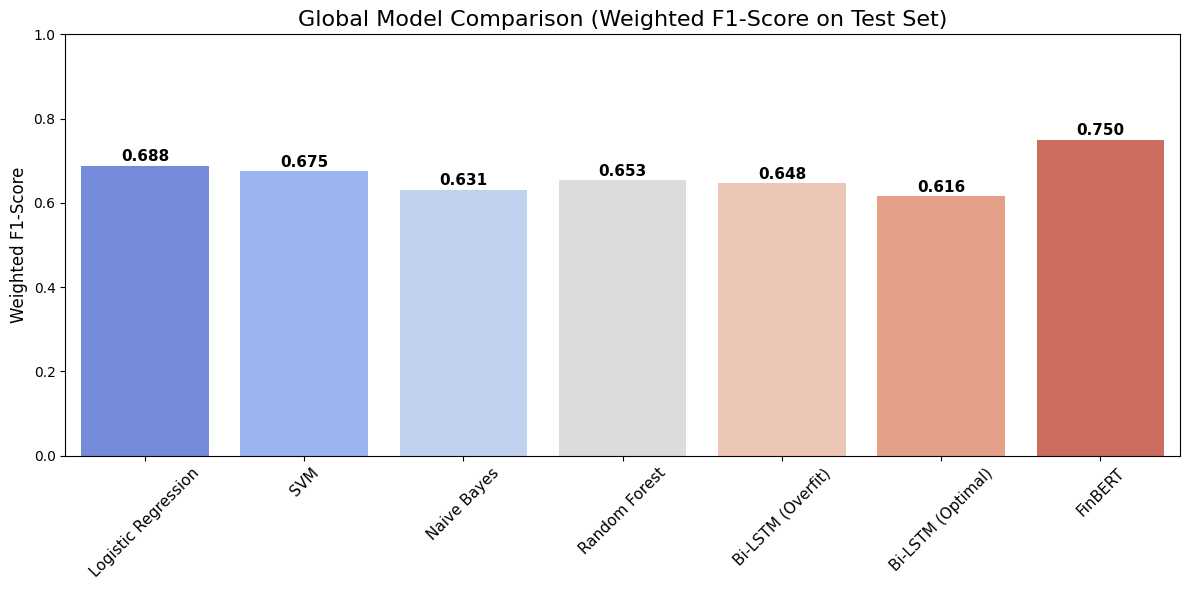

In [23]:
# Generate Global Bar Chart
plt.figure(figsize=(12, 6))

keys = list(f1_scores.keys())
values = list(f1_scores.values())

ax = sns.barplot(x=keys, y=values, hue=keys, palette='coolwarm', legend=False)
plt.title('Global Model Comparison (Weighted F1-Score on Test Set)', fontsize=16)
plt.ylabel('Weighted F1-Score', fontsize=12)
plt.ylim(0, 1)
plt.xticks(rotation=45, fontsize=11)

# Annotate values
for i, v in enumerate(values):
 ax.text(i, v + 0.01, f"{v:.3f}", ha='center', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()
